# 03 — Presentation-Based Forward Split, Baselines (LogReg & LightGBM), SHAP & Sensitivity Checks (`P1-B3`)

- **Split Protocol (`AUD-07`):** Train `2013B+2013J` · Validation `2014B` (`60% val_select` / `40% val_calib` untouched) · **Locked Test `2014J` untouched**.
- **Calendar Disclosure:** `2013J` (Oct 2013–Jun 2014) overlaps ~4 months with `2014B` (Feb 2014–Oct 2014); `Train 2013 -> Test 2014J` (Oct 2014) has zero calendar overlap.
- **SHAP Disclaimer:** Predictive attribution only — **NOT** causal drivers of dropout.

In [1]:
import json
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from oulad.baselines import run_p1_b3_validation_suite
from oulad.config import FIGURES_DIR, PROCESSED_DIR, REPORTS_DIR, SEED

# Run into an isolated temp directory to verify bit-for-bit reproducibility without overwriting
# the combined 3-model reports/metrics_val.json (which also includes TabularMLP from NB 04).
with tempfile.TemporaryDirectory() as tmpdir:
    tmp = Path(tmpdir)
    metrics_val, cutoff_df = run_p1_b3_validation_suite(
        processed_dir=PROCESSED_DIR,
        reports_dir=tmp / "reports",
        figures_dir=tmp / "figures",
        seed=SEED,
    )

assert metrics_val["split_protocol"]["test_2014j_untouched"] is True
committed_val = json.loads((REPORTS_DIR / "metrics_val.json").read_text(encoding="utf-8"))
for model_key in ("logistic_regression", "lightgbm"):
    assert metrics_val["models_val_select_t28_operational"][model_key] == (
        committed_val["models_val_select_t28_operational"][model_key]
    )

print("2014J locked:", metrics_val["split_protocol"]["test_2014j_untouched"])
print("Verified 100% exact match with committed reports/metrics_val.json.")
display(pd.DataFrame(metrics_val["models_val_select_t28_operational"]).T)

C:\Users\nguye\Downloads\AI_Engineer\oulad-early-warning\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['submission_rate_due']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\nguye\Downloads\AI_Engineer\oulad-early-warning\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['submission_rate_due']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


C:\Users\nguye\Downloads\AI_Engineer\oulad-early-warning\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['submission_rate_due']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\nguye\Downloads\AI_Engineer\oulad-early-warning\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['submission_rate_due']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


C:\Users\nguye\Downloads\AI_Engineer\oulad-early-warning\.venv\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


2014J locked: True
Verified 100% exact match with committed reports/metrics_val.json.


,n,n_pos,positive_rate,pr_auc,roc_auc,brier_score,best_iteration
logistic_regression,3905.0,1891.0,0.4843,0.7815,0.7791,0.1911,NaN
lightgbm,3905.0,1891.0,0.4843,0.7871,0.7842,0.1880,218.0


In [2]:
# Separate models across Operational vs Safe Common Cohort for T = 14, 21, 28
display(cutoff_df)

,mode,cutoff,model,n_train,n_val_select,n_features,positive_rate,pr_auc,roc_auc,brier_score,best_iteration
0,operational,14,logistic_regression,12075,3993,35,0.4961,0.6874,0.7038,0.2217,NaN
1,operational,14,lightgbm,12075,3993,35,0.4961,0.7026,0.7130,0.2190,186.0
2,operational,21,logistic_regression,12009,3948,36,0.4901,0.7601,0.7601,0.1991,NaN
3,operational,21,lightgbm,12009,3948,36,0.4901,0.7527,0.7575,0.2000,231.0
4,operational,28,logistic_regression,11806,3905,37,0.4843,0.7815,0.7791,0.1911,NaN
5,operational,28,lightgbm,11806,3905,37,0.4843,0.7871,0.7842,0.1880,218.0
6,common,14,logistic_regression,11797,3901,35,0.4842,0.6780,0.7017,0.2217,NaN
7,common,14,lightgbm,11797,3901,35,0.4842,0.6856,0.7070,0.2202,128.0
8,common,21,logistic_regression,11797,3901,36,0.4842,0.7539,0.7603,0.1988,NaN
9,common,21,lightgbm,11797,3901,36,0.4842,0.7394,0.7542,0.2014,209.0


=== Returning vs New (val_select, T=28) ===
{
  "logistic_regression": {
    "returning_pct": 10.14,
    "returning": {
      "n": 396,
      "n_pos": 243,
      "positive_rate": 0.6136,
      "pr_auc": 0.8608,
      "roc_auc": 0.812,
      "brier_score": 0.1678
    },
    "new": {
      "n": 3509,
      "n_pos": 1648,
      "positive_rate": 0.4696,
      "pr_auc": 0.7658,
      "roc_auc": 0.7699,
      "brier_score": 0.1937
    }
  },
  "lightgbm": {
    "returning_pct": 10.14,
    "returning": {
      "n": 396,
      "n_pos": 243,
      "positive_rate": 0.6136,
      "pr_auc": 0.8514,
      "roc_auc": 0.7976,
      "brier_score": 0.1748
    },
    "new": {
      "n": 3509,
      "n_pos": 1648,
      "positive_rate": 0.4696,
      "pr_auc": 0.7748,
      "roc_auc": 0.7778,
      "brier_score": 0.1895
    }
  }
}

=== Sensitivity Checks (val_select, T=28) ===
{
  "sensitive_demographic_ablation": {
    "dropped_columns": [
      "gender",
      "disability",
      "imd_band"
    ],
   

,feature,mean_abs_shap
0,mean_score,0.4685
1,submission_rate_due,0.3488
2,code_module,0.2673
3,highest_education,0.2603
4,mean_days_late,0.1905
5,active_days,0.1348
6,imd_band,0.1298
7,clicks_w1,0.1104
8,region,0.0902
9,last_click_day,0.0817


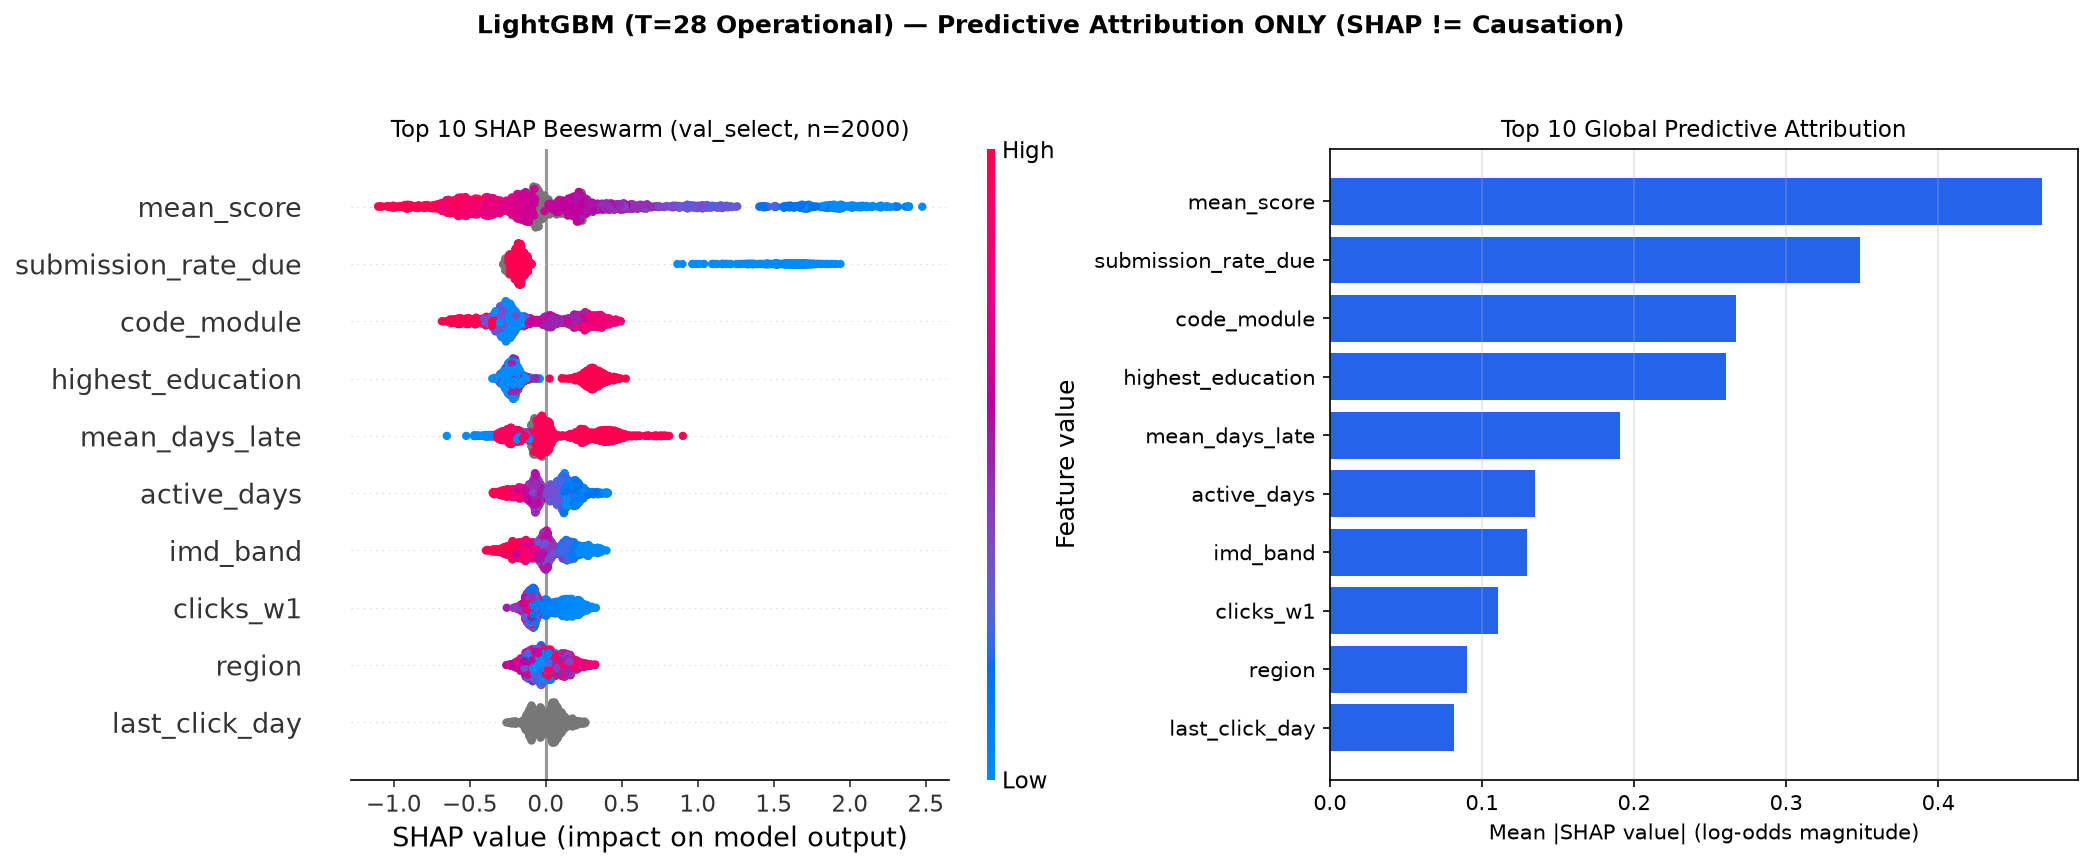

In [3]:
# Returning vs New Students + Priority B Sensitivity Checks + Non-Causal SHAP on val_select
print("=== Returning vs New (val_select, T=28) ===")
print(json.dumps(metrics_val["returning_vs_new_val_select_t28"], indent=2))
print("\n=== Sensitivity Checks (val_select, T=28) ===")
print(json.dumps(metrics_val["sensitivity_checks_val_select_t28"], indent=2))
print("\n=== Top 10 SHAP Predictive Attribution (Non-Causal) ===")
display(pd.DataFrame(metrics_val["shap_val_select_t28_lightgbm"]["top_10_features"]))
display(Image(filename=str(FIGURES_DIR / "shap_summary.png")))